# **Customer Analysis**

In [41]:
import pandas as pd
import numpy
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from matplotlib.ticker import FuncFormatter

In [42]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [43]:
ecommerce_df = pd.read_csv(
    'dataset/processed/ecommerce_processed.csv',
    parse_dates=['order_date']
)

In [44]:
def currency_formatter(x, _):
    if x >= 1_000_000_000:
        val = x / 1e9
        return f'${val:.1f}B'.replace('.0B', 'B')
    elif x >= 1_000_000:
        val = x / 1e6
        return f'${val:.1f}M'.replace('.0M', 'M')
    elif x >= 1_000:
        val = x / 1e3
        return f'${val:.1f}K'.replace('.0K', 'K')
    else:
        return f'${x:,.0f}'

## 1. Load Only Relevant Columns

In [45]:
CUSTOMER_COLUMNS = [
    # Year
    'order_year',
    
    # CUSTOMER PROFILE
    'customer_name',
    'gender',
    'age',
    'age_group',
    'customer_segment',
    'country',

    # PURCHASE BEHAVIOR
    'quantity',
    'net_revenue_usd',
    'profit_usd',
    'profit_margin_percent',
    'order_value_segment',

    # LOYALTY
    'customer_loyalty_score',
    'loyalty_tier',

    # ENGAGEMENT
    'session_duration_min',
    'engagement_level',
    'pages_visited',

    # CUSTOMER JOURNEY
    'abandoned_cart_before',
    'coupon_used',

    # DEVICE / ACQUISITION
    'device_type',
    'traffic_source',
]

In [46]:
customer_df = ecommerce_df[CUSTOMER_COLUMNS].copy()

In [47]:
customer_df.sample(10)

,order_year,customer_name,gender,age,age_group,customer_segment,country,quantity,net_revenue_usd,profit_usd,profit_margin_percent,order_value_segment,customer_loyalty_score,loyalty_tier,session_duration_min,engagement_level,pages_visited,abandoned_cart_before,coupon_used,device_type,traffic_source
300353,2024,Rachel Parker,Female,48,45-54,VIP,Netherlands,1,96.47,45.74,47.41,Low,30.60,Medium,10.70,Low,15,No,Yes,Desktop,Email
68230,2025,Marissa Robinson,Female,20,18-24,Regular,Belgium,5,864.31,448.16,51.85,Very High,94.80,High,23.90,Medium,9,Yes,No,Mobile,Referral
333441,2024,Justin Austin,Male,70,65+,Regular,Netherlands,1,73.58,26.08,35.44,Low,30.90,Medium,11.40,Low,3,No,No,Mobile,Direct
480200,2025,Dr. Rachel Yates,Female,42,35-44,Regular,Germany,5,642.64,167.49,26.06,Very High,84.90,High,49.30,High,19,Yes,No,Desktop,Referral
879034,2025,Jesus Reyes,Male,67,65+,Premium,Italy,2,358.72,150.32,41.90,High,0.50,Low,31.10,Medium,13,No,No,Desktop,Search
905254,2025,Brian Riley,Male,63,55-64,Premium,Italy,3,284.42,106.55,37.46,Medium,19.60,Low,30.40,Medium,20,Yes,No,Tablet,Referral
508904,2024,Danielle Mejia,Female,30,25-34,Premium,Spain,1,156.47,80.05,51.16,Medium,72.40,High,57.40,High,4,Yes,No,Tablet,Social
209143,2025,Angel Turner,Female,67,65+,Premium,Italy,2,34.00,7.52,22.12,Low,11.50,Low,43.30,High,7,Yes,Yes,Mobile,Social
32652,2025,Billy Washington,Male,71,65+,Regular,France,5,742.42,216.77,29.20,Very High,12.80,Low,41.80,High,12,Yes,Yes,Desktop,Search
648827,2024,Jennifer Maxwell,Female,59,55-64,Regular,France,5,"2,279.19",710.69,31.18,Very High,52.70,Medium,32.30,Medium,16,Yes,No,Tablet,Direct


## 2. Customer Overview (KPIs)

In [48]:
print(f"Total Transactions      :   {customer_df.shape[0]:,}")
print(f"Countries Covered       :   {customer_df['country'].nunique()}")
print(f"Customer Segments       :   {customer_df['customer_segment'].nunique()}")
print(f"Average Age             :   {customer_df['age'].mean():.2f}")
print(f"Average Loyalty         :   {customer_df['customer_loyalty_score'].mean():.2f}")

Total Transactions      :   1,000,123
Countries Covered       :   10
Customer Segments       :   3
Average Age             :   46.49
Average Loyalty         :   49.97


## 3. Customer Demographics

### 3.1 Customer Age Distribution

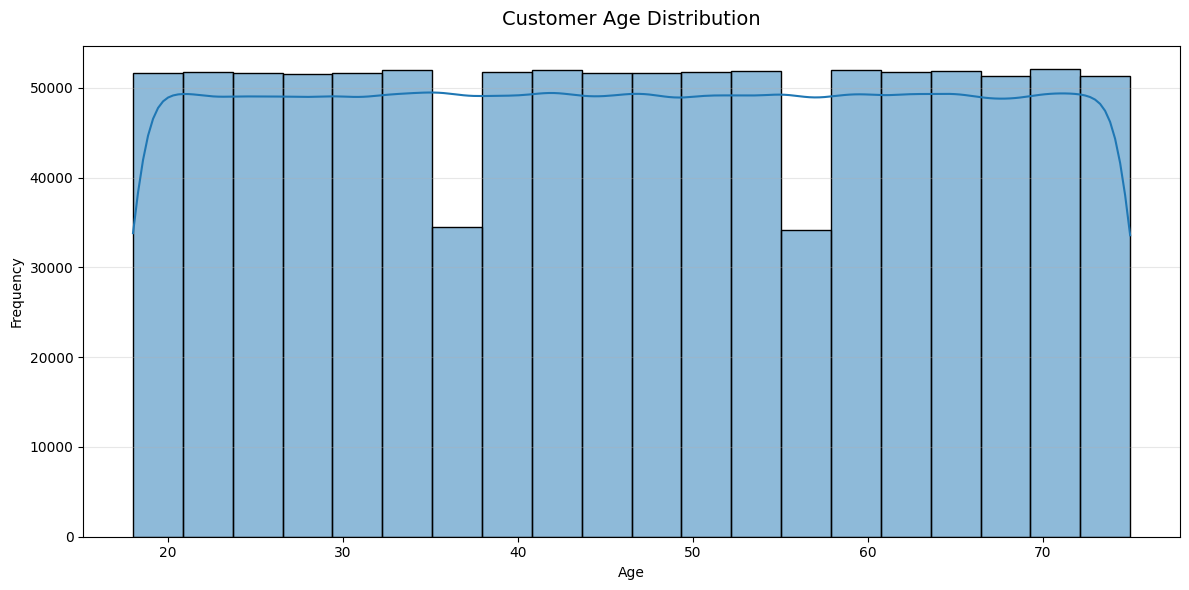

In [49]:
plt.figure(figsize=(12, 6))

ax = sns.histplot(
    data=customer_df,
    x='age',
    bins=20,
    kde=True
)

plt.title('Customer Age Distribution', fontsize=14, pad=15)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2 Average Transaction Value by Age Group

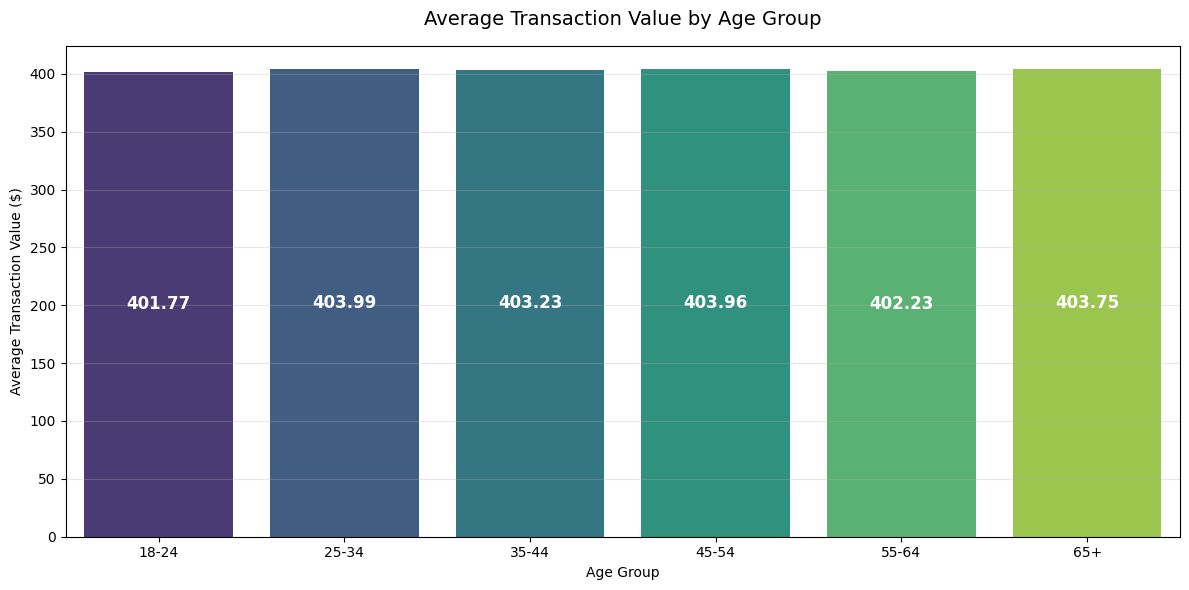

In [50]:
age_value = (
    customer_df
    .groupby('age_group', observed=True)
    .agg(
        avg_transaction_value=('net_revenue_usd', 'mean'),
        total_revenue=('net_revenue_usd', 'sum')
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=age_value,
    x='age_group',
    y='avg_transaction_value',
    palette='viridis',
    hue='age_group',
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.2f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Average Transaction Value by Age Group', fontsize=14, pad=15)
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Value ($)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 3.3 Customer Transactions by Gender Across Year

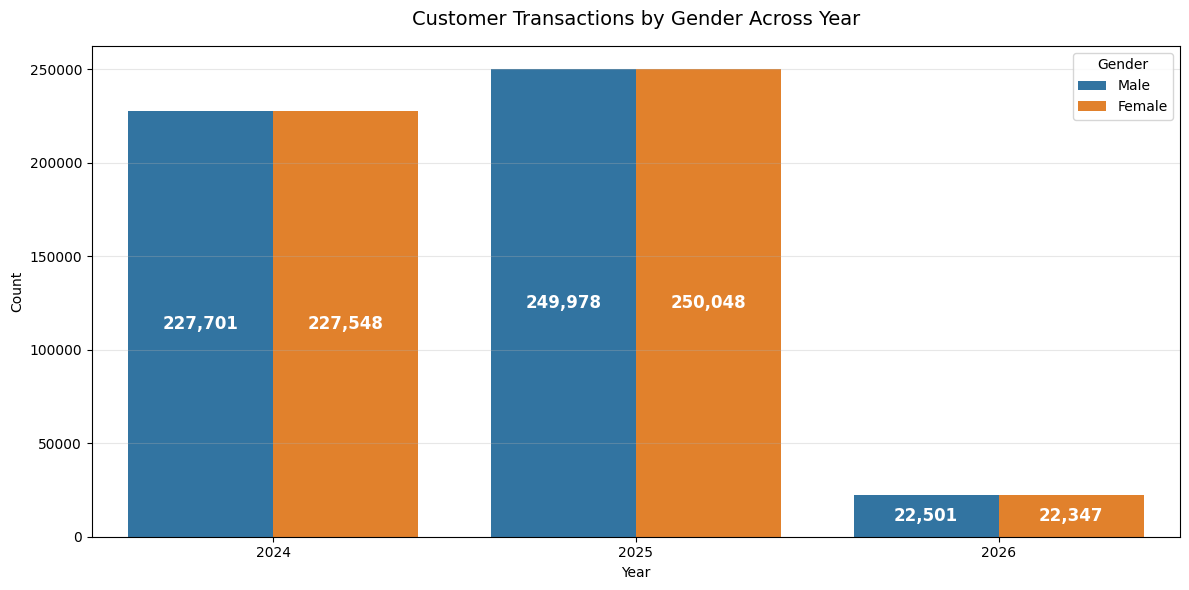

In [51]:
transaction_gender = (
    customer_df
    .groupby('order_year')['gender']
    .value_counts()
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=transaction_gender,
    x='order_year',
    y='count',
    hue='gender'
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Customer Transactions by Gender Across Year', fontsize=14, pad=15)
plt.xlabel('Year')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Customer Segment Analysis

### 4.1 Average Transaction Value by Customer Segment Across Year

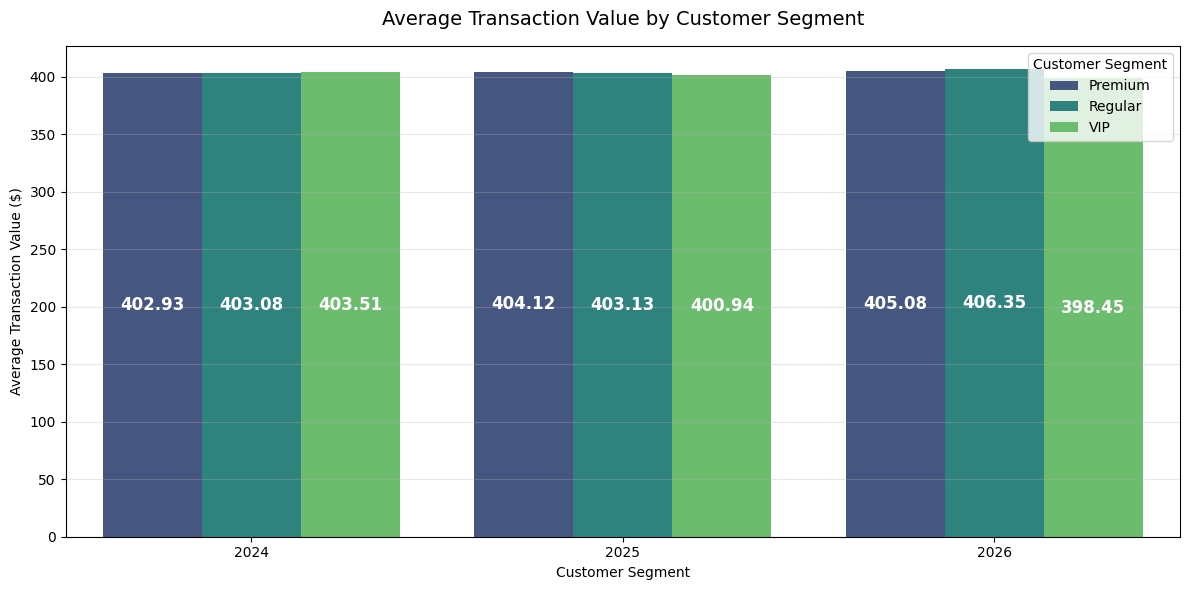

In [52]:
customer_value = (
    customer_df
    .groupby(['order_year', 'customer_segment'])
    .agg(
        avg_transaction_value=('net_revenue_usd', 'mean'),
        total_revenue=('net_revenue_usd', 'sum')
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=customer_value,
    x='order_year',
    y='avg_transaction_value',
    palette='viridis',
    hue='customer_segment',
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.2f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Average Transaction Value by Customer Segment', fontsize=14, pad=15)
plt.xlabel('Customer Segment')
plt.ylabel('Average Transaction Value ($)')
plt.legend(title='Customer Segment')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Customer Loyalty

### 5.1 Loyalty Tier Distribution by Customer Segment

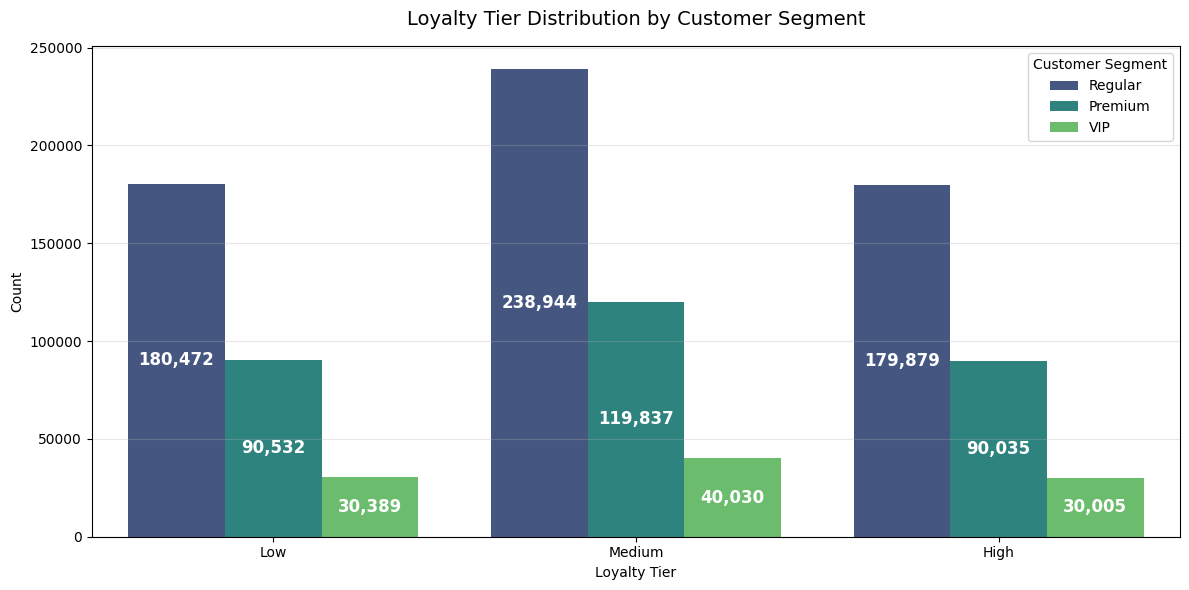

In [53]:
loyalty_tier_distribution = (
    customer_df
    .groupby(['customer_segment', 'loyalty_tier'])
    .size()
    .reset_index(name='count')
)

segment_order = ['Regular', 'Premium', 'VIP']
tier_order = ['Low', 'Medium', 'High']

loyalty_tier_distribution['customer_segment'] = pd.Categorical(
    loyalty_tier_distribution['customer_segment'],
    categories=segment_order,
    ordered=True
)
loyalty_tier_distribution['loyalty_tier'] = pd.Categorical(
    loyalty_tier_distribution['loyalty_tier'],
    categories=tier_order,
    ordered=True
)

loyalty_tier_distribution = loyalty_tier_distribution.sort_values(
    ['customer_segment', 'loyalty_tier']
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=loyalty_tier_distribution,
    x='loyalty_tier',
    y='count',
    hue='customer_segment',
    palette='viridis'
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Loyalty Tier Distribution by Customer Segment', fontsize=14, pad=15)
plt.xlabel('Loyalty Tier')
plt.ylabel('Count')
plt.legend(title='Customer Segment')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 5.2 Loyalty Score vs Transaction Value

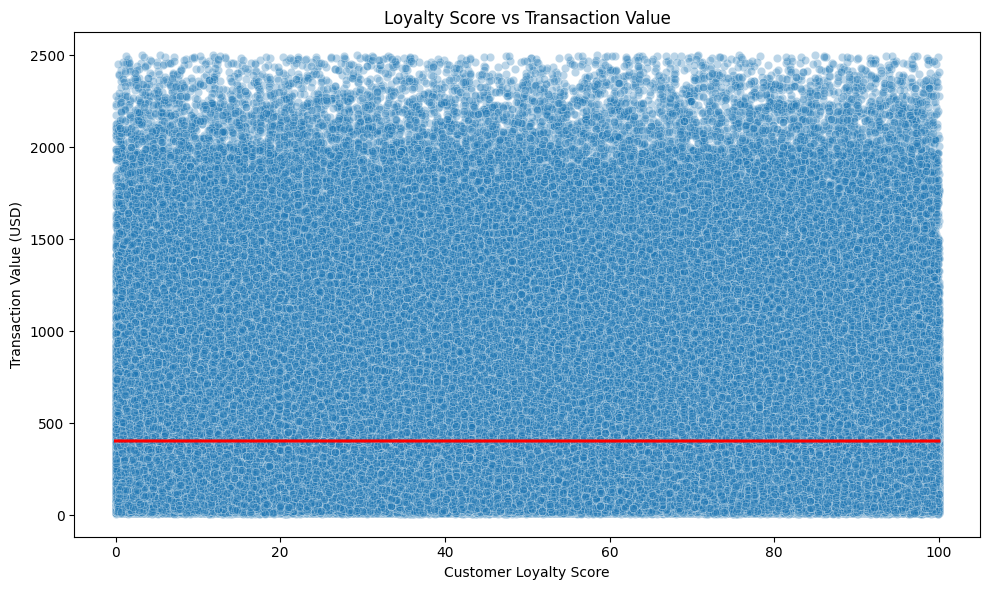

In [ ]:


plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=customer_df,
    x="customer_loyalty_score",
    y="net_revenue_usd",
    alpha=0.3
)

sns.regplot(
    data=customer_df,
    x="customer_loyalty_score",
    y="net_revenue_usd",
    scatter=False,
    color="red"
)

plt.title("Loyalty Score vs Transaction Value")
plt.xlabel("Customer Loyalty Score")
plt.ylabel("Transaction Value (USD)")
plt.tight_layout()
plt.show()

## 6. Customer Engagement

### 6.1 Engagement Level Distribution

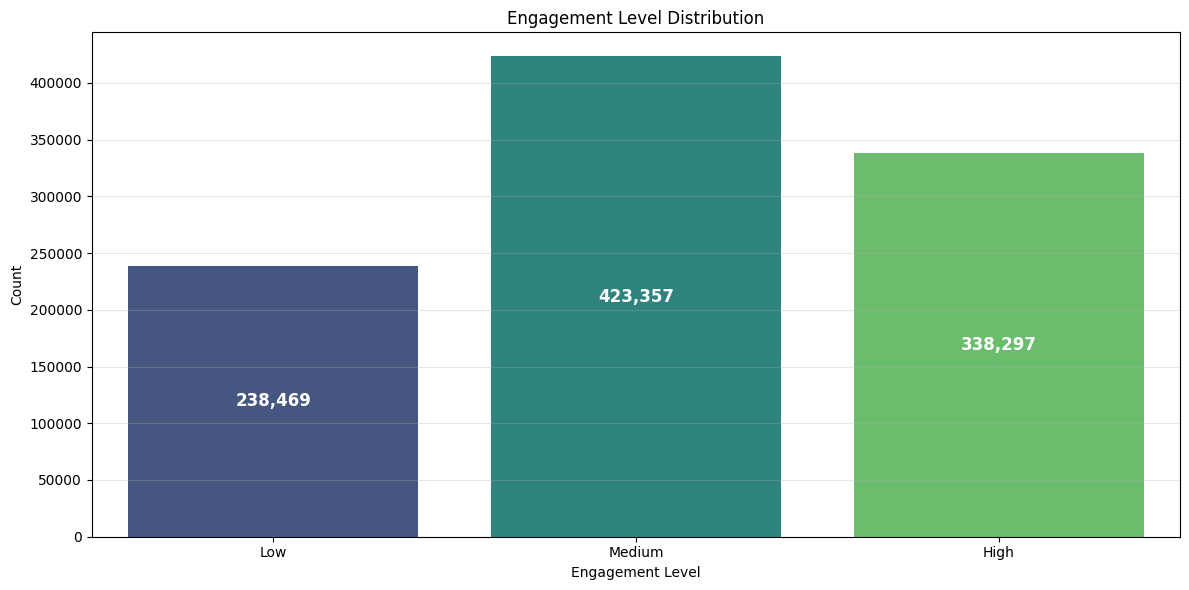

In [55]:
engagement_distribution = (
    customer_df['engagement_level']
    .value_counts()
    .reindex(['Low', 'Medium', 'High'])
    .reset_index()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=engagement_distribution,
    x='engagement_level',
    y='count',
    palette='viridis',
    hue='engagement_level',
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title("Engagement Level Distribution")
plt.xlabel("Engagement Level")
plt.ylabel("Count")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 6.2 Engagement Level vs Transaction Value

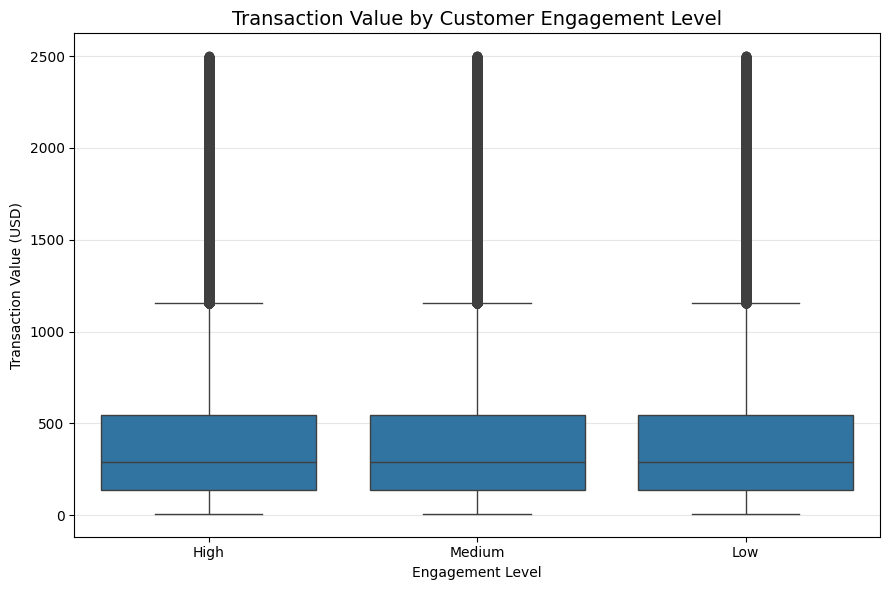

In [56]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=customer_df,
    x='engagement_level',
    y='net_revenue_usd'
)

plt.title('Transaction Value by Customer Engagement Level', fontsize=14)
plt.xlabel('Engagement Level')
plt.ylabel('Transaction Value (USD)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 6.2 Session Engagement vs Purchase Quantity

C:\Users\User\AppData\Local\Temp\ipykernel_5260\605701915.py:16: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\User\Desktop\gethub\Ecommerce-EDA-and-Sales-Prediction\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


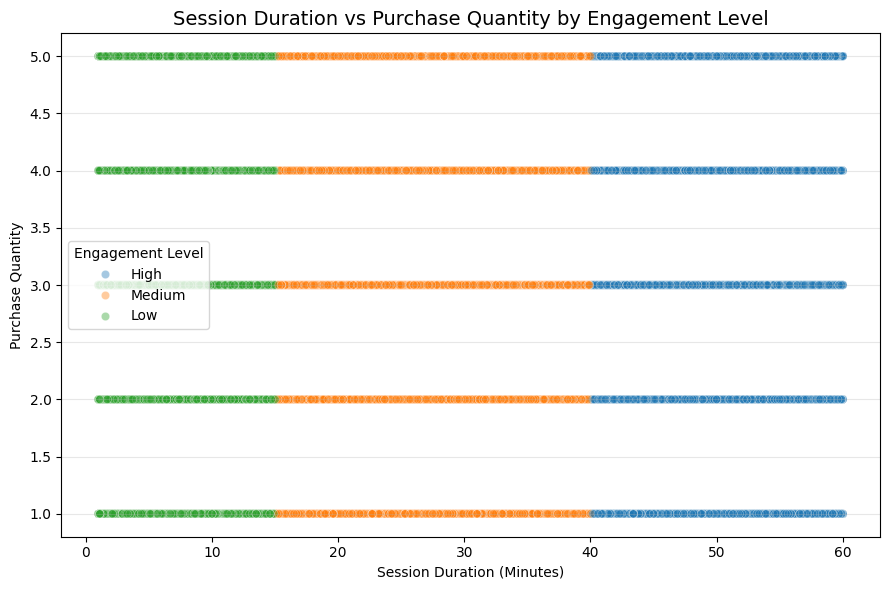

In [ ]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=customer_df,
    x='session_duration_min',
    y='quantity',
    hue='engagement_level',
    alpha=0.4
)

plt.title('Session Duration vs Purchase Quantity by Engagement Level', fontsize=14)
plt.xlabel('Session Duration (Minutes)')
plt.ylabel('Purchase Quantity')
plt.legend(title='Engagement Level')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Purchase Behavior

### 7.1 Previous Cart Abandonment

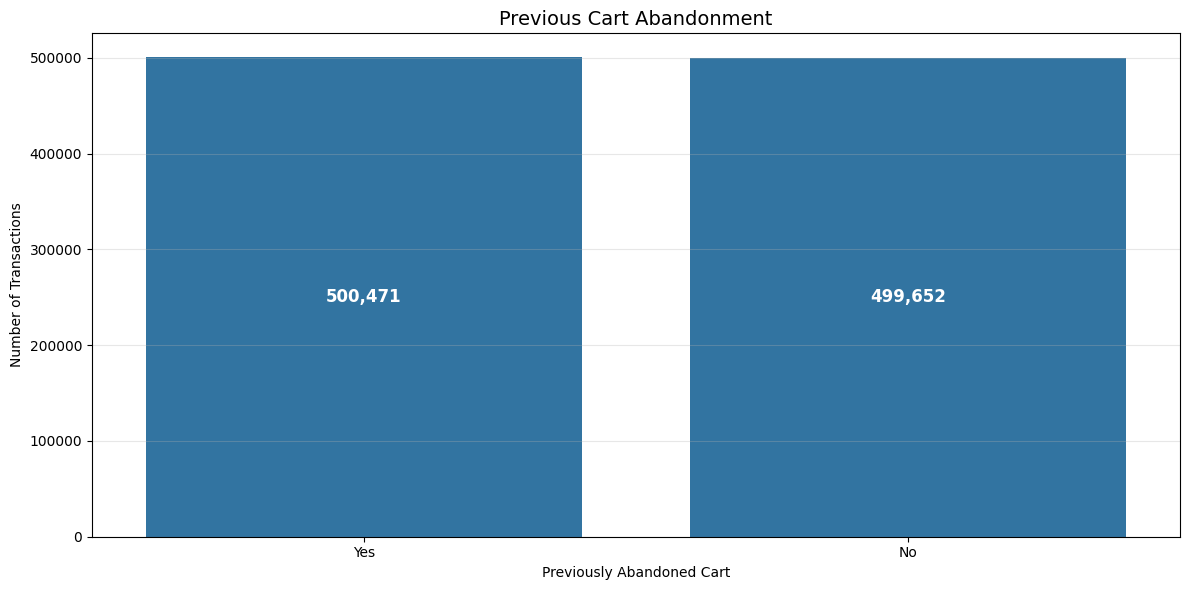

In [58]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=customer_df,
    x='abandoned_cart_before',
    order=['Yes', 'No']
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Previous Cart Abandonment', fontsize=14)
plt.xlabel('Previously Abandoned Cart')
plt.ylabel('Number of Transactions')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 7.2 Transaction Value by Cart Abandonment

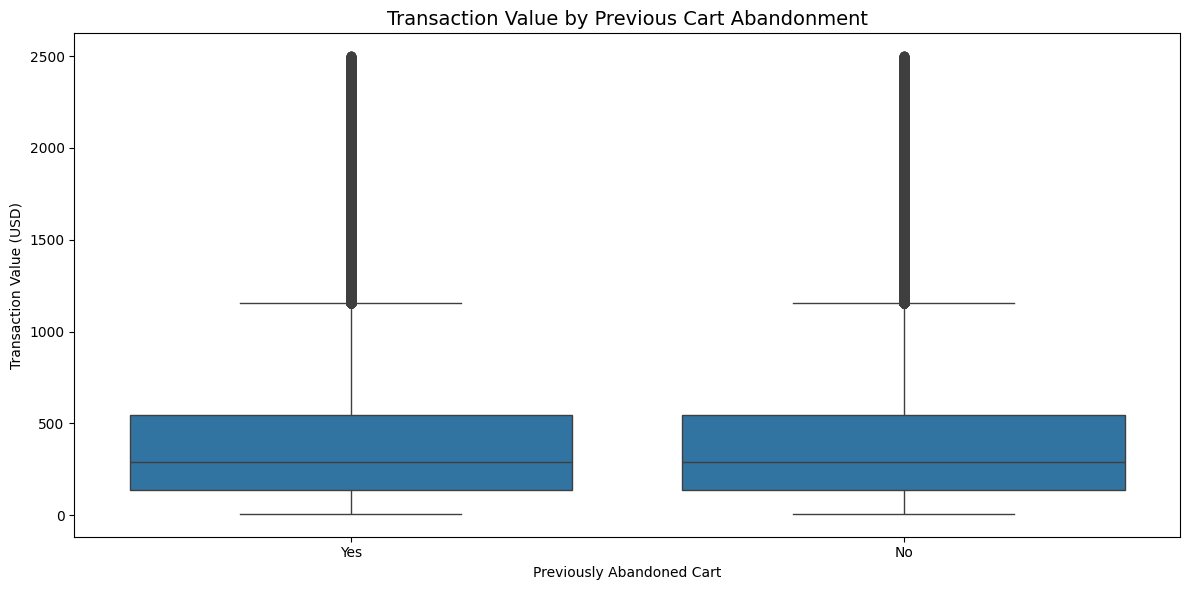

In [59]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=customer_df,
    x='abandoned_cart_before',
    y='net_revenue_usd',
    order=['Yes', 'No']
)

plt.title('Transaction Value by Previous Cart Abandonment', fontsize=14)
plt.xlabel('Previously Abandoned Cart')
plt.ylabel('Transaction Value (USD)')

plt.tight_layout()
plt.show()

### 7.3 Cart Abandonment and Profitability

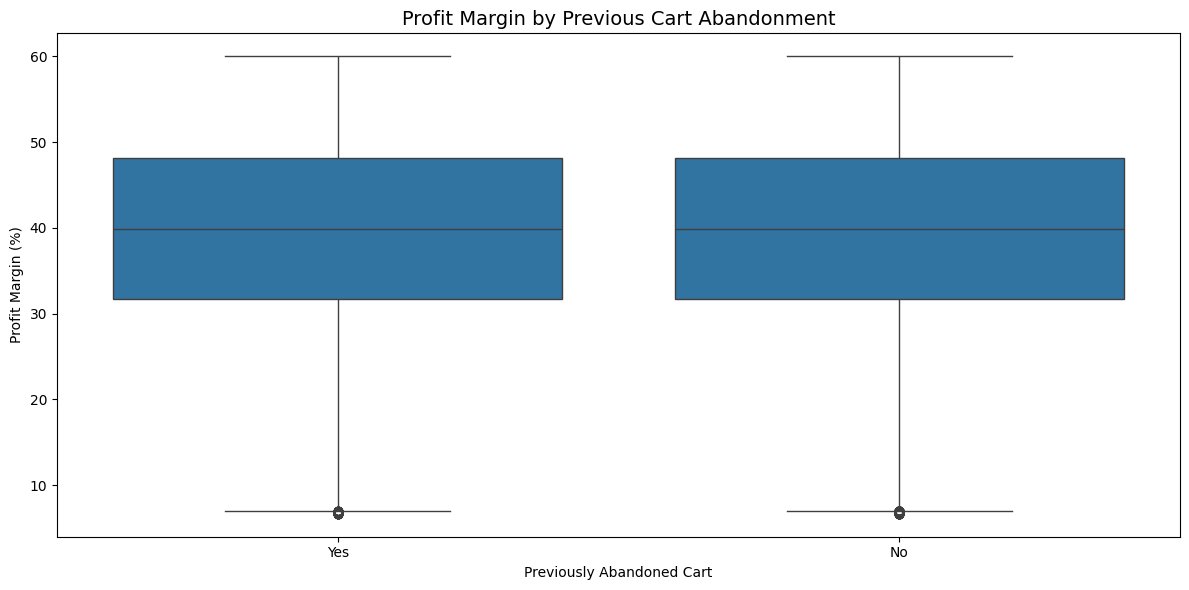

In [60]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=customer_df,
    x='abandoned_cart_before',
    y='profit_margin_percent',
    order=['Yes', 'No']
)

plt.title('Profit Margin by Previous Cart Abandonment', fontsize=14)
plt.xlabel('Previously Abandoned Cart')
plt.ylabel('Profit Margin (%)')

plt.tight_layout()
plt.show()

## 8. Customer Acquisition

### 8.1 Average Transaction Value by Traffic Source

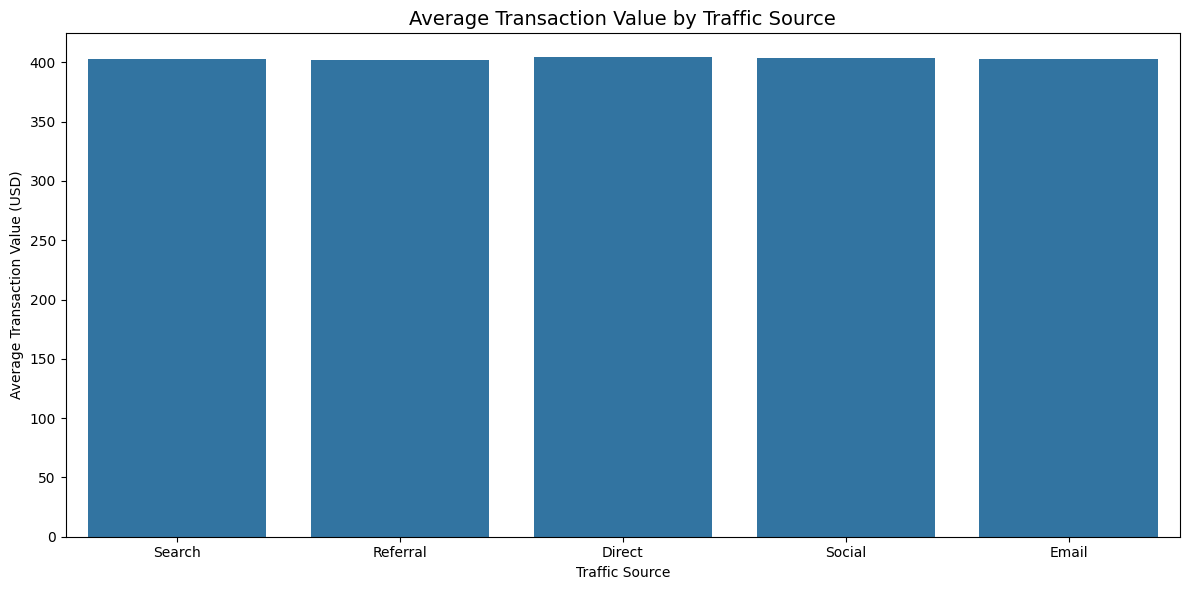

In [61]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=customer_df,
    x='traffic_source',
    y='net_revenue_usd',
    estimator='mean',
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Average Transaction Value by Traffic Source', fontsize=14)
plt.xlabel('Traffic Source')
plt.ylabel('Average Transaction Value (USD)')
plt.tight_layout()
plt.show()

### 8.2 Profitability by Traffic Source

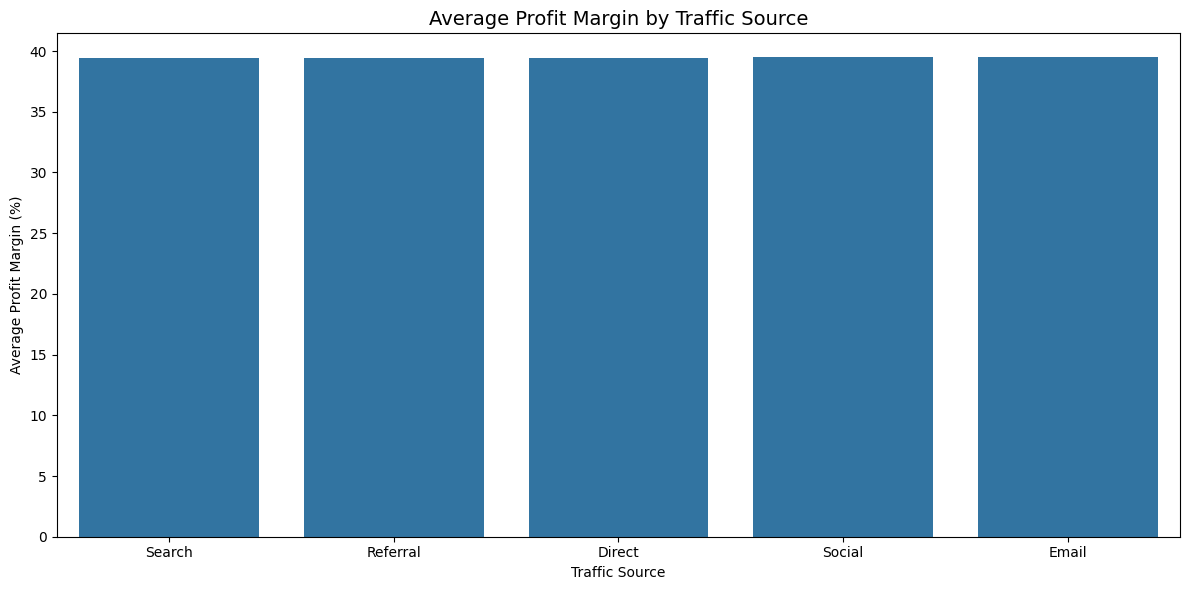

In [64]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=customer_df,
    x='traffic_source',
    y='profit_margin_percent',
    estimator='mean',
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f'{v:,.0f}' for v in container.datavalues],
        label_type='center',          
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.title('Average Profit Margin by Traffic Source', fontsize=14)
plt.xlabel('Traffic Source')
plt.ylabel('Average Profit Margin (%)')
plt.tight_layout()
plt.show()

## 9. Customer Value

### 9.1 Customer Segment x Order Value Segment

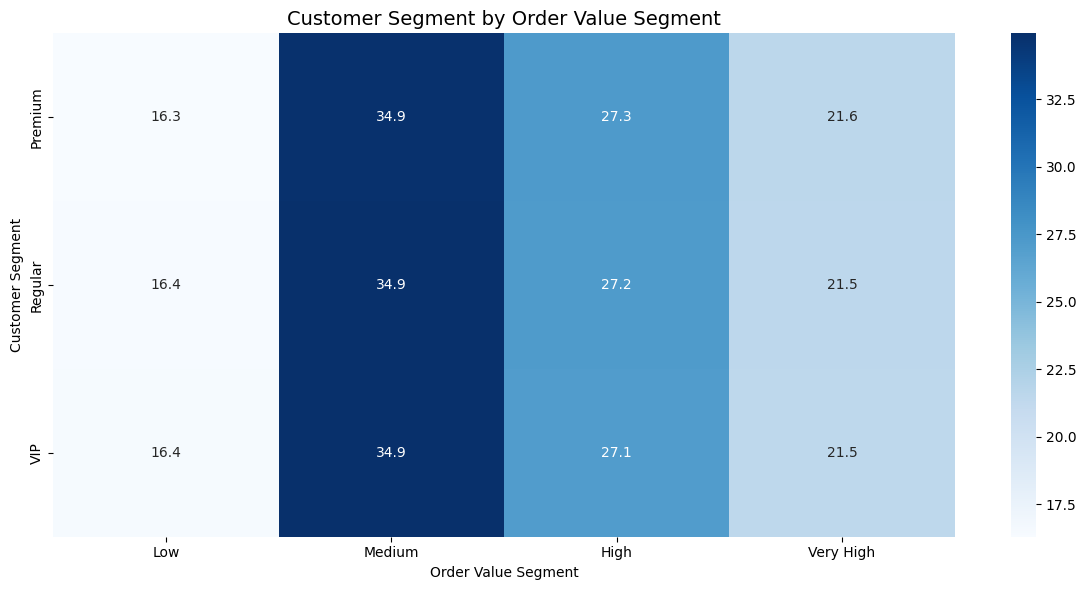

In [63]:
value_matrix = pd.crosstab(
    customer_df['customer_segment'],
    customer_df['order_value_segment'],
    normalize='index'
) * 100

value_matrix = value_matrix.reindex(columns=['Low', 'Medium', 'High', 'Very High'])

plt.figure(figsize=(12, 6))

sns.heatmap(
    value_matrix,
    annot=True,
    fmt='.1f',
    cmap='Blues',
)

plt.title('Customer Segment by Order Value Segment', fontsize=14)
plt.xlabel('Order Value Segment')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()